In [2]:
import functools
import os
import sys

from ultralytics import YOLO
import pandas as pd

sys.path.append("..")
import ultralytics_validator_wrapper
from tflite_inference import TFLiteInferer
from tflite_inference_input_adapter import TFLiteInferenceWithInputAdapter

pd.options.display.float_format = '{:.3f}'.format

%matplotlib inline
%load_ext autoreload
%autoreload 2

TensorFlow version:  2.17.0


In [3]:
# WEIGHTS_PTH = "../results/filtered_v3_margin_15_reduced_quality/weights/best.pt"
WEIGHTS_PTH = "../results/filtered_v3_margin_15_yolo11/weights/best.pt"

BASE_PTH = "/home/klymy/projects/researches/people_detection_pg2/quality_reduce_comparison/cam4_poc_15_blurred_grayscale"
BAELINE_BASE_PTH = "/home/klymy/projects/researches/people_detection_pg2/quality_reduce_comparison/cam4_poc_15"

VAL_PTH = os.path.join(BASE_PTH, "project_pg.yaml")
BASELINE_VAL_PTH = os.path.join(BAELINE_BASE_PTH, "project_pg.yaml")

CONF_TH = 0.25
IOU_TH = 0.55

args = dict(
    data=VAL_PTH,
    task="pose",
    device=[0],
    batch=128,
    verbose=False,
    conf=CONF_TH,
    iou=IOU_TH,
    imgsz=320,
    model="val",
    rect=False,
    single_cls=False,
)

args_baseline = args.copy()
args_baseline["data"] = BASELINE_VAL_PTH

In [4]:
model = YOLO(WEIGHTS_PTH)

val: Scanning /home/klymy/projects/researches/people_detection_pg2/quality_reduce_comparison/cam4_poc_15_blurred_grayscale/labels/val.cache... 191 images, 5 backgrounds, 0 corrupt: 100%|██████████| 191/191 [00:00<?, ?it/s]


tst validation: 100%|██████████| 2/2 [00:03<00:00,  1.53s/it]


                   all        191        417       0.89      0.756       0.86      0.503       0.91      0.773      0.877      0.876
   task    F1     P     R  MAP@50
0   box 0.817 0.890 0.756   0.860
1  pose 0.836 0.910 0.773   0.877


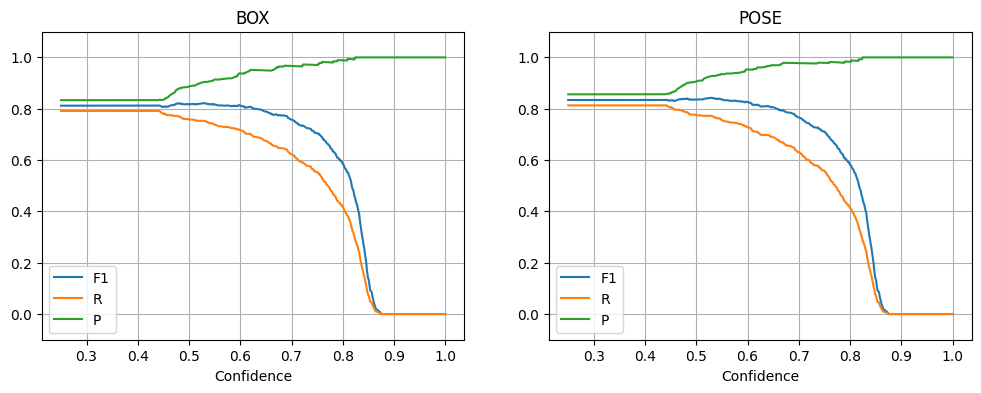

In [5]:
ultralytics_validator_wrapper.validate_model(
    args,
    model,
    functools.partial(ultralytics_validator_wrapper.predict_ultralytics, model, args),
)

In [6]:
# inferer = TFLiteInferer(
#     yolo_pth="../results/filtered_v3_margin_15_reduced_quality/weights/best_saved_model/best_full_integer_quant.tflite",
#     head_pth="../results/filtered_v3_margin_15_reduced_quality/weights/head_saved_model/head_float32.tflite",
#     conf_th=CONF_TH,
#     iou_th=IOU_TH,
#     imgsz=320,
# )
inferer = TFLiteInferer(
    yolo_pth="../results/filtered_v3_margin_15_yolo11/weights/best_saved_model/best_full_integer_quant.tflite",
    head_pth="../results/filtered_v3_margin_15_yolo11/weights/head_saved_model/head_float32.tflite",
    conf_th=CONF_TH,
    iou_th=IOU_TH,
    imgsz=320,
)

INFO: Created TensorFlow Lite XNNPACK delegate for CPU.


val: Scanning /home/klymy/projects/researches/people_detection_pg2/quality_reduce_comparison/cam4_poc_15_blurred_grayscale/labels/val.cache... 191 images, 5 backgrounds, 0 corrupt: 100%|██████████| 191/191 [00:00<?, ?it/s]
tst validation:   0%|          | 0/2 [00:00<?, ?it/s]

tst validation: 100%|██████████| 2/2 [00:07<00:00,  3.80s/it]


                   all        191        417      0.865      0.612      0.764      0.433      0.821      0.669      0.791      0.784
   task    F1     P     R  MAP@50
0   box 0.716 0.865 0.612   0.764
1  pose 0.737 0.821 0.669   0.791


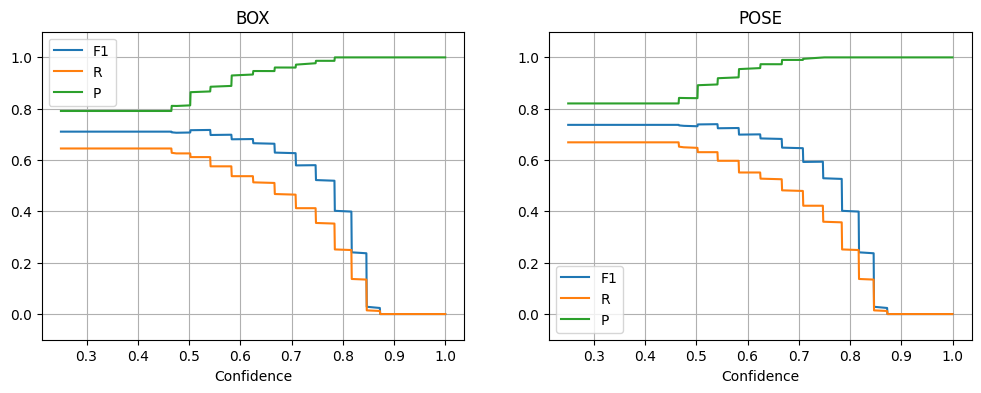

In [7]:
ultralytics_validator_wrapper.validate_model(
    args,
    model,
    functools.partial(ultralytics_validator_wrapper.predict_tflite, inferer, args)
)

In [8]:
# inferer_adapter = TFLiteInferenceWithInputAdapter(
#     yolo_pth="../results/filtered_v3_margin_15_reduced_quality/weights/best_saved_model/best_full_integer_quant.tflite",
#     head_pth="../results/filtered_v3_margin_15_reduced_quality/weights/head_saved_model/head_float32.tflite",
#     adapter_pth="../input_adapter/input_adapter_full_integer_quant.tflite",
#     conf_th=CONF_TH,
#     iou_th=IOU_TH,
#     imgsz=320,
# )

inferer_adapter = TFLiteInferenceWithInputAdapter(
    yolo_pth="../results/filtered_v3_margin_15_yolo11/weights/best_saved_model/best_full_integer_quant.tflite",
    head_pth="../results/filtered_v3_margin_15_yolo11/weights/head_saved_model/head_float32.tflite",
    adapter_pth="../input_adapter/input_adapter_full_integer_quant.tflite",
    conf_th=CONF_TH,
    iou_th=IOU_TH,
    imgsz=320,
)

val: Scanning /home/klymy/projects/researches/people_detection_pg2/quality_reduce_comparison/cam4_poc_15/labels/val.cache... 191 images, 5 backgrounds, 0 corrupt: 100%|██████████| 191/191 [00:00<?, ?it/s]


tst validation: 100%|██████████| 2/2 [00:08<00:00,  4.46s/it]


                   all        191        417      0.556       0.71      0.609      0.293      0.591      0.753       0.68      0.654
   task    F1     P     R  MAP@50
0   box 0.624 0.556 0.710   0.609
1  pose 0.663 0.591 0.753   0.680


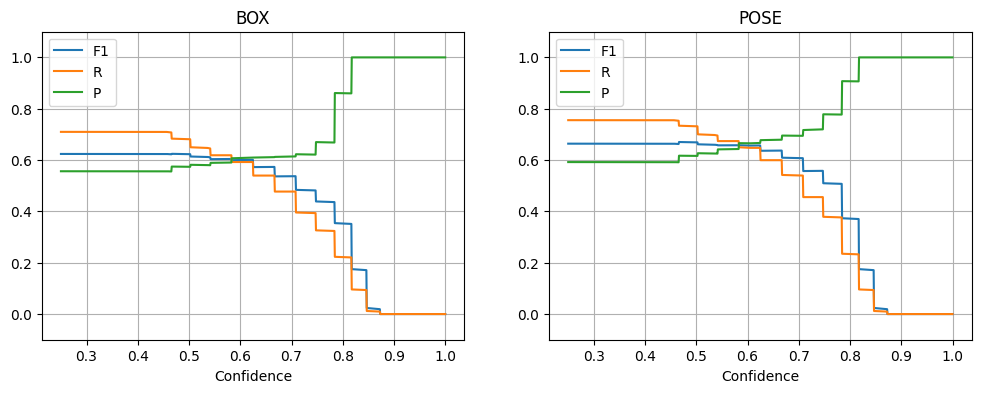

In [9]:
ultralytics_validator_wrapper.validate_model(
    args_baseline,
    model,
    functools.partial(ultralytics_validator_wrapper.predict_tflite, inferer_adapter, args_baseline)
)

In [ ]:
# YOLO 8
#    task    F1     P     R  MAP@50
# 0   box 0.854 0.925 0.794   0.884
# 1  pose 0.877 0.950 0.815   0.900